# Supervised Learning Experiments


---

# Initialization <a name="2"></a>

---

## Import Libraries

Every import of the notebook is kept in this cell.

In [210]:
%pip install matplotlib numpy pandas scikit-learn cvxpy


Python(97190) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Note: you may need to restart the kernel to use updated packages.


In [211]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, OrdinalEncoder

from sklearn.feature_selection import SelectKBest, VarianceThreshold, mutual_info_classif
from sklearn.decomposition import PCA

# Support starting the notebook from the repository root or docs directory.
ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "src").is_dir():
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


## Settings

Paths and shared constants are kept in this class.

In [212]:
class Settings:
    SEED = 42
    DATA_DIR = ROOT_DIR / "docs"
    OUTPUT_DIR = ROOT_DIR / "output"

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [213]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [214]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding <a name="3"></a>

---

## Explore Data
Memahami nya seperti memahami dia


In [215]:
print(train_df.shape)
train_df.dtypes

(27373, 19)


id                              str
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
meal_package                    str
needs_parking               float64
room_category                   str
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
booking_channel                 str
is_returning_guest            int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
is_canceled                   int64
dtype: object

In [216]:
train_df.head()

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


In [217]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


#### Distribusi Fitur Kategorikal

In [218]:
train_df["meal_package"].value_counts()


meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
Full Board        4
Name: count, dtype: int64

In [219]:
train_df["room_category"].value_counts()

room_category
Type B    20447
Type G     4396
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64

In [220]:
train_df["booking_channel"].value_counts()

booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64

####  Distribusi is_cancelled

In [221]:
print(train_df["is_canceled"].value_counts())
print(train_df["is_canceled"].value_counts(normalize=True))

is_canceled
0    18404
1     8969
Name: count, dtype: int64
is_canceled
0    0.672341
1    0.327659
Name: proportion, dtype: float64


In [222]:
pd.crosstab(
    train_df["booking_channel"],
    train_df["is_canceled"],
    normalize="index"
)

is_canceled,0,1
booking_channel,,
Airline,0.693182,0.306818
Complimentary,1.000000,0.000000
Corporate,0.884997,0.115003
Offline Agent,0.698492,0.301508
Online Travel Agent,0.636343,0.363657


In [223]:
pd.crosstab(
    train_df["meal_package"],
    train_df["is_canceled"],
    normalize="index"
)

is_canceled,0,1
meal_package,,
Breakfast,0.688562,0.311438
Full Board,0.750000,0.250000
Half Board,0.540589,0.459411
Room Only,0.661998,0.338002


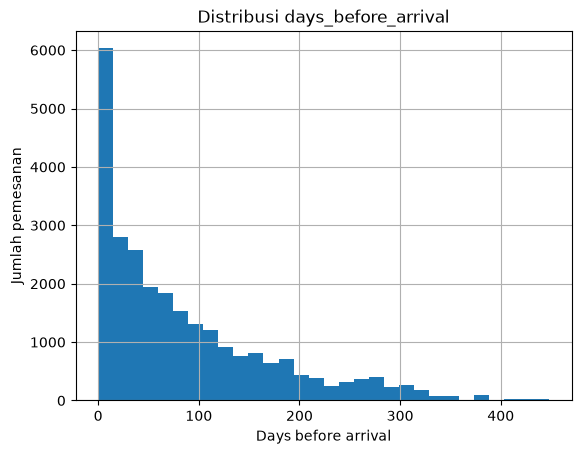

In [224]:
train_df["days_before_arrival"].hist(bins=30)
plt.xlabel("Days before arrival")
plt.ylabel("Jumlah pemesanan")
plt.title("Distribusi days_before_arrival")
plt.show()

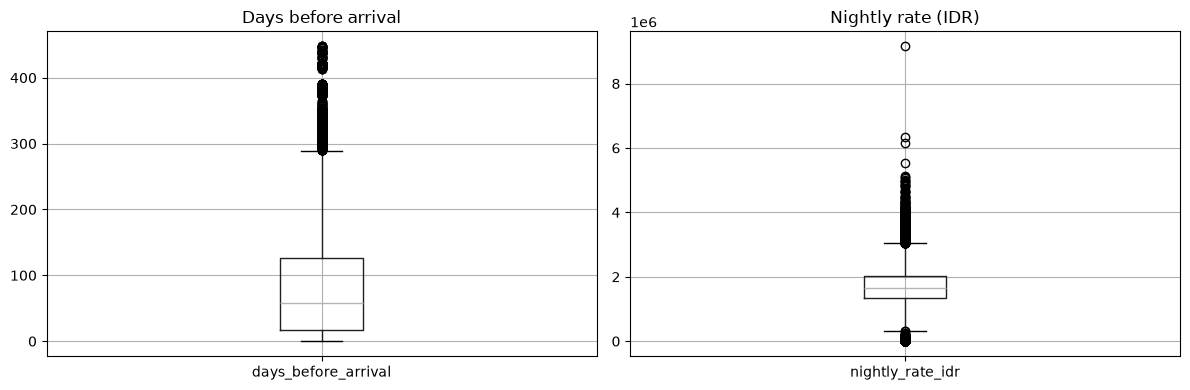

In [225]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df.boxplot(column="days_before_arrival", ax=axes[0])
axes[0].set_title("Days before arrival")

train_df.boxplot(column="nightly_rate_idr", ax=axes[1])
axes[1].set_title("Nightly rate (IDR)")

plt.tight_layout()
plt.show()

In [226]:
train_df.groupby("is_canceled")["days_before_arrival"].describe()

,count,mean,std,min,25%,50%,75%,max
is_canceled,,,,,,,,
0,17631.0,58.913221,63.722946,0.0,10.0,38.0,86.0,390.0
1,8619.0,139.518622,99.195754,0.0,55.0,123.0,205.5,448.0


## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [227]:
feature_cols = test_df.columns

missing_summary = pd.DataFrame({
    "train": train_df[feature_cols].isna().sum(),
    "test": test_df.isna().sum()
})

missing_summary[missing_summary.sum(axis=1) > 0]

,train,test
num_adults,809,180
num_children,3035,747
meal_package,1760,442
needs_parking,1082,247
room_category,1002,242
days_before_arrival,1123,290
nightly_rate_idr,2038,540
special_requests,2500,593


In [228]:
print("Duplikat baris train:", train_df.duplicated().sum())
print("ID duplikat train:", train_df["id"].duplicated().sum())

print("Duplikat baris test:", test_df.duplicated().sum())
print("ID duplikat test:", test_df["id"].duplicated().sum())


Duplikat baris train: 0
ID duplikat train: 0
Duplikat baris test: 0
ID duplikat test: 0


In [229]:
nonnegative_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
]

train_df[nonnegative_cols].lt(0).sum()

num_adults                  0
num_children                0
weekend_nights              0
weekday_nights              0
days_before_arrival         0
prior_cancellations         0
prior_completed_bookings    0
nightly_rate_idr            0
special_requests            0
dtype: int64

In [230]:
print("num_adults = 0:", (train_df["num_adults"] == 0).sum())
print("arrival_month di luar 1–12:", (~train_df["arrival_month"].between(1, 12)).sum())
print("arrival_day di luar 1–31:", (~train_df["arrival_day"].between(1, 31)).sum())

num_adults = 0: 106
arrival_month di luar 1–12: 0
arrival_day di luar 1–31: 0


In [231]:
train_features = train_df.drop(columns="is_canceled")

print("Kolom train dan test sama:", train_features.columns.equals(test_df.columns))

for col in ["meal_package", "room_category", "booking_channel"]:
    unseen = set(test_df[col].dropna().unique()) - set(train_df[col].dropna().unique())
    print(f"{col}, kategori baru di test:", unseen)

Kolom train dan test sama: True
meal_package, kategori baru di test: set()
room_category, kategori baru di test: set()
booking_channel, kategori baru di test: set()


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [232]:
ID_COL = "id"
TARGET_COL = "is_canceled"

X = train_df.drop(columns=[ID_COL, TARGET_COL])
y = train_df[TARGET_COL].astype(int)
X_test = test_df.drop(columns=[ID_COL])
test_ids = test_df[ID_COL].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=CFG.SEED
)

pd.Series({
    "X_train": len(X_train),
    "X_val": len(X_val),
    "X_test": len(X_test),
})


X_train    21898
X_val       5475
X_test      6844
dtype: int64

---

# Data Preparation <a name="5"></a>

---

## Select Data

In [233]:
train_ids = train_df.loc[X_train.index, ID_COL].copy()
val_ids = train_df.loc[X_val.index, ID_COL].copy()

X_train_raw = X_train.copy()
X_val_raw = X_val.copy()
X_test_raw = X_test.copy()

print("Jumlah fitur:", X_train.shape[1])
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape)


Jumlah fitur: 17
Train: (21898, 17) (21898,)
Validation: (5475, 17) (5475,)
Test: (6844, 17)


## Clean Data

Cleaning raises data quality to the level the chosen models need.

In [234]:
num_col = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "needs_parking", "days_before_arrival", "arrival_year",
    "arrival_month", "arrival_day", "is_returning_guest",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests",
]
cat_col = ["meal_package", "room_category", "booking_channel"]


### Missing Values

In [235]:
train_zero_adults = X_train_raw["num_adults"].eq(0)
val_zero_adults = X_val_raw["num_adults"].eq(0)
test_zero_adults = X_test_raw["num_adults"].eq(0)

print("num_adults = 0 pada train:", int(train_zero_adults.sum()))
print("num_adults = 0 pada validation:", int(val_zero_adults.sum()))
print("num_adults = 0 pada test:", int(test_zero_adults.sum()))

X_train_raw.loc[train_zero_adults, "num_adults"] = np.nan
X_val_raw.loc[val_zero_adults, "num_adults"] = np.nan
X_test_raw.loc[test_zero_adults, "num_adults"] = np.nan

numeric_fill_values = X_train_raw[num_col].median()
categorical_fill_values = X_train_raw[cat_col].mode(dropna=True).iloc[0]

def impute_missing_values(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()
    result[num_col] = result[num_col].fillna(numeric_fill_values)
    result[cat_col] = result[cat_col].fillna(categorical_fill_values)
    return result

X_train_imputed = impute_missing_values(X_train_raw)
X_val_imputed = impute_missing_values(X_val_raw)
X_test_imputed = impute_missing_values(X_test_raw)

print("Missing value setelah imputasi (train):", int(X_train_imputed.isna().sum().sum()))
print("Missing value setelah imputasi (validation):", int(X_val_imputed.isna().sum().sum()))
print("Missing value setelah imputasi (test):", int(X_test_imputed.isna().sum().sum()))

num_adults = 0 pada train: 84
num_adults = 0 pada validation: 22
num_adults = 0 pada test: 22
Missing value setelah imputasi (train): 0
Missing value setelah imputasi (validation): 0
Missing value setelah imputasi (test): 0


### Duplicates

In [236]:
train_rows = X_train_raw.copy()
train_rows[ID_COL] = train_ids
train_rows[TARGET_COL] = y_train
val_rows = X_val_raw.copy()
val_rows[ID_COL] = val_ids
val_rows[TARGET_COL] = y_val

print("Duplikat train:", int(train_rows.duplicated().sum()))
print("Duplikat validation:", int(val_rows.duplicated().sum()))
print("Duplikat test:", int(test_df.duplicated().sum()))

X_train_clean = X_train_imputed.copy()
X_val_clean = X_val_imputed.copy()
X_test_clean = X_test_imputed.copy()


Duplikat train: 0
Duplikat validation: 0
Duplikat test: 0


### Outliers

In [237]:
outlier_cols = [
    "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr", "special_requests",
]
outlier_counts = {}

for col in outlier_cols:
    values = X_train_raw[col].dropna()
    if col == "nightly_rate_idr":
        values = values[values > 0]
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    source = X_train_raw[col]
    eligible = source.notna()
    if col == "nightly_rate_idr":
        eligible &= source > 0
    outlier_counts[col] = int((eligible & ((source < lower) | (source > upper))).sum())

pd.Series(outlier_counts, name="kandidat_outlier_IQR")


num_children                1613
weekend_nights                13
weekday_nights               201
days_before_arrival          755
prior_cancellations          183
prior_completed_bookings     478
nightly_rate_idr             574
special_requests             456
Name: kandidat_outlier_IQR, dtype: int64

### Data Errors

In [238]:
negative_counts = X_train_raw[num_col].lt(0).sum()

binary_cols = ["needs_parking", "is_returning_guest", TARGET_COL]
binary_values = X_train_raw[["needs_parking", "is_returning_guest"]].copy()
binary_values[TARGET_COL] = y_train
invalid_binary_counts = (
    (~binary_values[binary_cols].isin([0, 1]) & binary_values[binary_cols].notna()).sum()
)

arrival_dates = pd.to_datetime(
    X_train_raw[["arrival_year", "arrival_month", "arrival_day"]]
    .rename(columns={
        "arrival_year": "year",
        "arrival_month": "month",
        "arrival_day": "day",
    }),
    errors="coerce",
)
invalid_arrival_dates = int(arrival_dates.isna().sum())

print("Nilai numerik negatif:", negative_counts[negative_counts > 0].to_dict())
print("Nilai biner di luar 0/1:", invalid_binary_counts[invalid_binary_counts > 0].to_dict())
print("Tanggal kedatangan tidak valid:", invalid_arrival_dates)


Nilai numerik negatif: {}
Nilai biner di luar 0/1: {}
Tanggal kedatangan tidak valid: 0


## Data Transformation

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [239]:
scaled_numeric_cols = num_col.copy()
scaler = RobustScaler()

X_train_scaled = X_train_clean.copy()
X_val_scaled = X_val_clean.copy()
X_test_scaled = X_test_clean.copy()

X_train_scaled[scaled_numeric_cols] = scaler.fit_transform(X_train_clean[scaled_numeric_cols])
X_val_scaled[scaled_numeric_cols] = scaler.transform(X_val_clean[scaled_numeric_cols])
X_test_scaled[scaled_numeric_cols] = scaler.transform(X_test_clean[scaled_numeric_cols])

print("Jumlah fitur numerik yang distandardisasi:", len(scaled_numeric_cols))


Jumlah fitur numerik yang distandardisasi: 14


### Encoding

This part covers the numeric representation of categorical attributes.

In [240]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train_scaled[cat_col])

encoded_feature_names = list(encoder.get_feature_names_out(cat_col))

meal_package_order = [
    "Room Only",
    "Breakfast",
    "Half Board",
    "Full Board",
]

meal_package_encoder = OrdinalEncoder(
    categories=[meal_package_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

meal_package_encoder.fit(X_train_scaled[["meal_package"]])

def combine_scaled_and_encoded(data: pd.DataFrame) -> pd.DataFrame:
    numeric_part = data[scaled_numeric_cols].copy()

    categorical_part = pd.DataFrame(
        encoder.transform(data[cat_col]),
        columns=encoded_feature_names,
        index=data.index,
    )

    categorical_part = categorical_part.drop(
        columns=[
            col for col in encoded_feature_names
            if col.startswith("meal_package_")
        ]
    )

    categorical_part["meal_package"] = meal_package_encoder.transform(
        data[["meal_package"]]
    ).ravel()

    return pd.concat([numeric_part, categorical_part], axis=1)

X_train_encoded = combine_scaled_and_encoded(X_train_scaled)
X_val_encoded = combine_scaled_and_encoded(X_val_scaled)
X_test_encoded = combine_scaled_and_encoded(X_test_scaled)

print("Bentuk fitur train:", X_train_encoded.shape)
print("Bentuk fitur validation:", X_val_encoded.shape)
print("Bentuk fitur test:", X_test_encoded.shape)

Bentuk fitur train: (21898, 27)
Bentuk fitur validation: (5475, 27)
Bentuk fitur test: (6844, 27)


## Feature Selection


Removed constant features: []
Feature scores:
days_before_arrival                    1.054516e-01
special_requests                       4.158404e-02
arrival_month                          2.709663e-02
nightly_rate_idr                       2.502356e-02
arrival_year                           2.456089e-02
prior_completed_bookings               9.457885e-03
is_returning_guest                     8.396625e-03
booking_channel_Corporate              6.796644e-03
booking_channel_Online Travel Agent    5.402483e-03
booking_channel_Complimentary          4.435582e-03
needs_parking                          4.223668e-03
weekend_nights                         4.181798e-03
num_adults                             3.982429e-03
meal_package                           3.238631e-03
arrival_day                            1.579500e-03
prior_cancellations                    7.718927e-04
booking_channel_Offline Agent          7.221817e-04
room_category_Type A                   5.127590e-04
room_category_Type

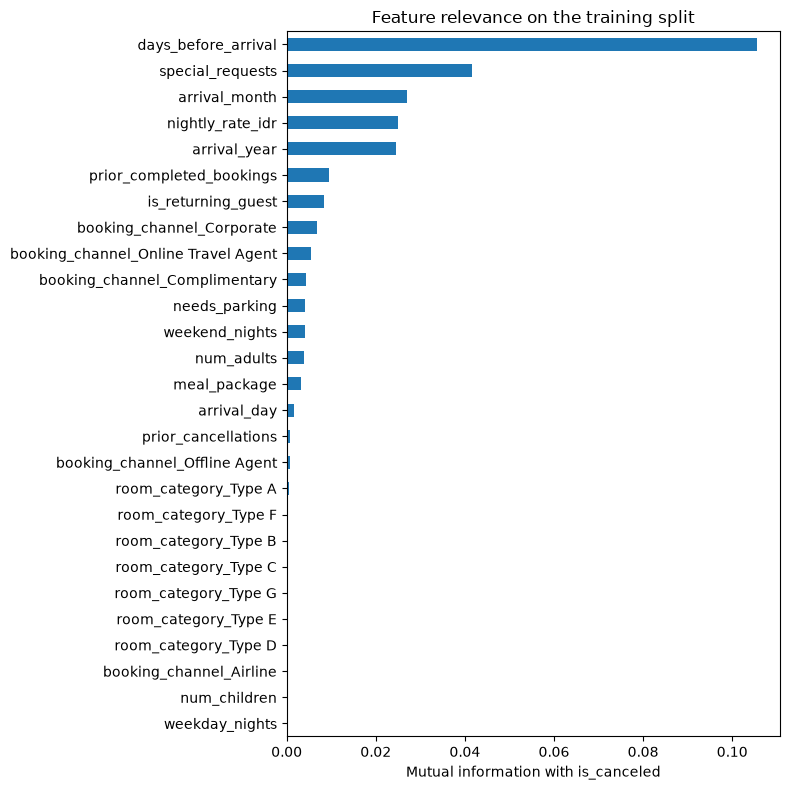

In [241]:
constant_filter = VarianceThreshold(threshold=0.0)
constant_filter.fit(X_train_encoded)
nonconstant_cols = X_train_encoded.columns[constant_filter.get_support()].tolist()
removed_constant_cols = X_train_encoded.columns[~constant_filter.get_support()].tolist()

# One-hot columns and binary flags are discrete, even after scaling.
discrete_features = np.array([
    col not in scaled_numeric_cols or col in ["needs_parking", "is_returning_guest"]
    for col in nonconstant_cols
])


def score_features(X, y):
    values = np.array(X, dtype=float, copy=True)
    # Give discrete features integer codes after their earlier standardization.
    for i, is_discrete in enumerate(discrete_features):
        if is_discrete:
            _, values[:, i] = np.unique(values[:, i], return_inverse=True)
    return mutual_info_classif(
        values, y, discrete_features=discrete_features, random_state=CFG.SEED
    )


SELECT_K = min(15, len(nonconstant_cols))
selector = SelectKBest(score_func=score_features, k=SELECT_K)
selector.fit(X_train_encoded[nonconstant_cols], y_train)
selected_cols = np.array(nonconstant_cols)[selector.get_support()].tolist()

feature_scores = pd.Series(
    selector.scores_, index=nonconstant_cols, name="mutual_information"
).sort_values(ascending=False)
print("Removed constant features:", removed_constant_cols)
print("Feature scores:")
print(feature_scores)
print("Selected features:", selected_cols)

X_train_selected = X_train_encoded[selected_cols].copy()
X_val_selected = X_val_encoded[selected_cols].copy()
X_test_selected = X_test_encoded[selected_cols].copy()

feature_scores.sort_values().plot.barh(figsize=(8, 8))
plt.xlabel("Mutual information with is_canceled")
plt.title("Feature relevance on the training split")
plt.tight_layout()
plt.show()

## Dimensionality Reduction


Selected feature count: 15
PCA component count: 13
Retained variance: 0.9501534905747309


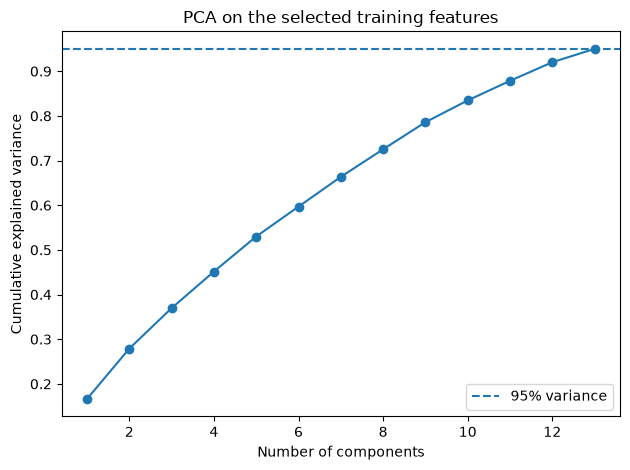

In [242]:
pca_scaler = StandardScaler()
pca_train = pca_scaler.fit_transform(X_train_selected)
pca_val = pca_scaler.transform(X_val_selected)
pca_test = pca_scaler.transform(X_test_selected)

pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pd.DataFrame(pca.fit_transform(pca_train), index=X_train_selected.index)
X_val_pca = pd.DataFrame(pca.transform(pca_val), index=X_val_selected.index)
X_test_pca = pd.DataFrame(pca.transform(pca_test), index=X_test_selected.index)

print("Selected feature count:", len(selected_cols))
print("PCA component count:", pca.n_components_)
print("Retained variance:", pca.explained_variance_ratio_.sum())

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA on the selected training features")
plt.legend()
plt.tight_layout()
plt.show()

### Class Balance

In [ ]:
y_train_cv = y_train.reset_index(drop=True).copy()

class_balance = pd.DataFrame({
    "jumlah": y_train.value_counts().sort_index(),
    "proporsi": y_train.value_counts(normalize=True).sort_index(),
})
class_balance.index.name = TARGET_COL
print("Distribusi sebelum oversampling:")
print(class_balance)

majority_indices = y_train[y_train == 0].index
minority_indices = y_train[y_train == 1].sample(
    n=len(majority_indices),
    replace=True,
    random_state=CFG.SEED,
).index
balanced_indices = majority_indices.append(minority_indices)
balanced_indices = pd.Series(balanced_indices).sample(
    frac=1,
    random_state=CFG.SEED,
).to_numpy()

X_train_final = X_train_encoded.loc[balanced_indices].reset_index(drop=True)
y_train_final = y_train.loc[balanced_indices].reset_index(drop=True)
X_val_final = X_val_encoded.copy()
X_test_final = X_test_encoded.copy()

print("Distribusi training setelah oversampling:")
print(y_train_final.value_counts().sort_index())


# Apply the same sampled row indices to each representation.
X_train_selected_final = X_train_selected.loc[balanced_indices].reset_index(drop=True)
X_val_selected_final = X_val_selected.copy()
X_test_selected_final = X_test_selected.copy()

X_train_pca_final = X_train_pca.loc[balanced_indices].reset_index(drop=True)
X_val_pca_final = X_val_pca.copy()
X_test_pca_final = X_test_pca.copy()

# Use the exact same 27-feature representation (X_train_final) for Naive Bayes too.
nb_binary_cols = ["needs_parking", "is_returning_guest"]
nb_numeric_cols = [col for col in num_col if col not in nb_binary_cols]
nb_categorical_cols = [col for col in X_train_final.columns if col not in nb_numeric_cols + nb_binary_cols]
X_train_nb = X_train_final.copy()
X_val_nb = X_val_final.copy()
X_test_nb = X_test_final.copy()
y_train_nb = y_train_final.copy()
y_val_nb = y_val.copy()

print("Full training features:", X_train_final.shape)
print("Selected training features:", X_train_selected_final.shape)
print("PCA training components:", X_train_pca_final.shape)
print("Mixed NB training features:", X_train_nb.shape)

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [244]:
X_train_model = X_train_final.to_numpy(dtype=float)
X_val_model = X_val_final.to_numpy(dtype=float)
X_test_model = X_test_final.to_numpy(dtype=float)
y_train_model = y_train_final.to_numpy(dtype=int)
y_val_model = y_val.to_numpy(dtype=int)

print("X_train_model, y_train_model:", X_train_model.shape, y_train_model.shape)
print("X_val_model, y_val_model:", X_val_model.shape, y_val_model.shape)
print("X_test_model:", X_test_model.shape)


X_train_model, y_train_model: (29446, 27) (29446,)
X_val_model, y_val_model: (5475, 27) (5475,)
X_test_model: (6844, 27)


# Model
## Scratch

In [ ]:
from src.knn import KNN
from src.NaiveBayes import NaiveBayes
from src.svm import svm
from src.dtl.c45 import DecisionTreeC45
from src.LogRes import LogRes

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB, BernoulliNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

### KNN

In [ ]:
knn_scratch = KNN(k=3)
knn_scratch.fit(X_train_model, y_train_model)
knn_val_pred = knn_scratch.predict(X_val_model)

knn_val_pred[:10]

### NaiveBayes

In [ ]:
nb_scratch = NaiveBayes(
    numeric_cols=nb_numeric_cols,
    categorical_cols=nb_categorical_cols,
    binary_cols=nb_binary_cols,
)
nb_scratch.fit(X_train_nb, y_train_nb)
nb_val_pred = nb_scratch.predict(X_val_nb)

### Naive Bayes Graph


In [ ]:
nb_graph_features = nb_scratch.numeric_cols_ + nb_scratch.categorical_cols_ + nb_scratch.binary_cols_
n_cols = 6
n_rows = int(np.ceil(len(nb_graph_features) / n_cols))
y_positions = np.linspace(0.74, 0.12, n_rows)

fig, ax = plt.subplots(figsize=(16, 9))
ax.text(0.5, 0.94, "is_canceled", ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.6", facecolor="lightblue"), zorder=3)
for i, feature in enumerate(nb_graph_features):
    x = 0.08 + (i % n_cols) * 0.168
    y = y_positions[i // n_cols]
    ax.annotate("", xy=(x, y + 0.03), xytext=(0.5, 0.90),
                arrowprops=dict(arrowstyle="->", color="gray", alpha=0.5))
    ax.text(x, y, feature.replace("_", "\n"), ha="center", va="center",
            fontsize=8, bbox=dict(boxstyle="round,pad=0.35", facecolor="white"),
            zorder=3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Naive Bayes: class-to-feature dependencies")
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / "NaiveBayes_graph.png", dpi=150)
plt.show()

### Cost-sensitive Classification


In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

nb_bonus_probabilities = nb_scratch.predict_proba(X_val_nb)
nb_canceled_column = list(nb_scratch.classes_).index(1)
nb_canceled_probability = nb_bonus_probabilities[:, nb_canceled_column]
nb_cost_rows = []
for name, threshold in [("Default", 0.5), ("Cost-sensitive", 2 / 3)]:
    predictions = (nb_canceled_probability > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val_nb, predictions, labels=[0, 1]).ravel()
    nb_cost_rows.append({
        "rule": name, "threshold": threshold,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "precision": precision_score(y_val_nb, predictions, zero_division=0),
        "recall": recall_score(y_val_nb, predictions, zero_division=0),
        "f1": f1_score(y_val_nb, predictions, zero_division=0),
        "total_cost": 2 * fp + fn,
    })
nb_cost_results = pd.DataFrame(nb_cost_rows).set_index("rule")
print(nb_cost_results.round(4).to_string())
nb_cost_reduction = int(
    nb_cost_results.loc["Default", "total_cost"]
    - nb_cost_results.loc["Cost-sensitive", "total_cost"]
)
print("Cost reduction (positive means improvement):", nb_cost_reduction)

fig, ax = plt.subplots(figsize=(6, 4))
nb_cost_results["total_cost"].plot.bar(ax=ax, rot=0)
ax.set_ylabel("Total cost = 2 * FP + FN")
ax.set_title("Validation cost at fixed thresholds")
fig.tight_layout()
plt.show()

### SVM

In [ ]:
svm_scratch = svm(kernel="rbf", gamma=0.1)
svm_scratch.fit(X_train_model, y_train_model)
svm_val_pred = svm_scratch.predict(X_val_model)

### Decision Tree Learning (DTL)

In [ ]:
# dtl here
from src.dtl.c45 import DecisionTreeC45
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, confusion_matrix, roc_curve,
)

def c45_tree_stats(node, depth=0):
    """Hitung jumlah leaf dan kedalaman pohon C4.5 scratch."""
    if node.is_leaf():
        return 1, depth
    leaves, max_depth = 0, depth
    for child in node.children:
        l, d = c45_tree_stats(child, depth + 1)
        leaves += l
        max_depth = max(max_depth, d)
    return leaves, max_depth

def evaluate_tree(name, model, X_tr, y_tr, X_va, y_va, kind):
    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    fit_time = time.perf_counter() - start

    pred = np.asarray(model.predict(X_va)).astype(int)
    proba = model.predict_proba(X_va)[:, list(model.classes_).index(1)]
    train_pred = np.asarray(model.predict(X_tr)).astype(int)

    if kind == "c45":
        leaves, depth = c45_tree_stats(model.tree_)
    else:
        leaves, depth = model.get_n_leaves(), model.get_depth()

    return {
        "Model": name,
        "Train Accuracy": accuracy_score(y_tr, train_pred),
        "Accuracy": accuracy_score(y_va, pred),
        "F1 (kelas 1)": f1_score(y_va, pred),
        "Macro-F1": f1_score(y_va, pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_va, proba),
        "Jumlah Leaf": leaves,
        "Kedalaman": depth,
        "Waktu Fit (s)": fit_time,
    }, pred, proba

def printFormated(data: dict):
   for key, val in data.items():
       print(f"{key} : {val}")

dtl_pruned = DecisionTreeC45(prune=True, confidence_factor=0.25)
dtl_unpruned = DecisionTreeC45(prune=False)

res_c45_pruned, pred_c45, proba_c45 = evaluate_tree(
    "C4.5 (pruned, CF=0.25)", dtl_pruned, X_train_final, y_train_final, X_val_final, y_val, "c45")
res_c45_unpruned, _, proba_c45_unpruned = evaluate_tree(
    "C4.5 (unpruned)", dtl_unpruned, X_train_final, y_train_final, X_val_final, y_val, "c45")
dtl_val_pred = pred_c45
print("=" * 20 + "pruned" + "=" * 20)
printFormated(res_c45_pruned)
print("=" * 20 + "unpruned" + "=" * 20)
printFormated(res_c45_unpruned)

In [274]:
dtl_pruned.tree_.to_text()

days_before_arrival <= 150.0: 
|    needs_parking > 0.0: 0 (567.0/3.0)
|    needs_parking <= 0.0: 
|    |    special_requests <= 0.0: 
|    |    |    booking_channel = Complimentary: 0 (100.0)
|    |    |    booking_channel = Offline Agent: 
|    |    |    |    days_before_arrival <= 56.0: 
|    |    |    |    |    weekend_nights <= 0: 
|    |    |    |    |    |    nightly_rate_idr <= 2577000.0: 0 (939.0/1.0)
|    |    |    |    |    |    nightly_rate_idr > 2577000.0: 
|    |    |    |    |    |    |    nightly_rate_idr <= 3358000.0: 0 (16.0)
|    |    |    |    |    |    |    nightly_rate_idr > 3358000.0: 1 (9.0)
|    |    |    |    |    weekend_nights > 0: 
|    |    |    |    |    |    arrival_day <= 27: 0 (668.0/46.0)
|    |    |    |    |    |    arrival_day > 27: 
|    |    |    |    |    |    |    weekday_nights > 1: 0 (38.0)
|    |    |    |    |    |    |    weekday_nights <= 1: 
|    |    |    |    |    |    |    |    arrival_month > 3: 0 (5.0)
|    |    |    |    |    |    

### Logistic Regression

In [251]:
logres_scratch = LogRes(
    learn_rate=0.01,
    iterations=300,
    penalty="l2",
    C=1.0,
    tolerance=1e-4,
    fit_intercept=True,
    shuffle=True,
    verbose=True,
    random_seed=CFG.SEED,
    # record_every=500,
)
logres_scratch.fit(X_train_model, y_train_model)
logres_val_pred = logres_scratch.predict(X_val_model)

Iteration 1/300, Log-Likelihood: -13990.8828
Iteration 2/300, Log-Likelihood: -14018.0574
Iteration 3/300, Log-Likelihood: -14029.4301
Iteration 4/300, Log-Likelihood: -13940.3935
Iteration 5/300, Log-Likelihood: -13989.4196
Iteration 6/300, Log-Likelihood: -13942.4891
Iteration 7/300, Log-Likelihood: -13962.1698
Iteration 8/300, Log-Likelihood: -14019.7844
Iteration 9/300, Log-Likelihood: -13930.9249
Iteration 10/300, Log-Likelihood: -13967.7103
Iteration 11/300, Log-Likelihood: -13975.7785
Iteration 12/300, Log-Likelihood: -13941.6915
Iteration 13/300, Log-Likelihood: -14065.1926
Iteration 14/300, Log-Likelihood: -14187.1174
Iteration 15/300, Log-Likelihood: -13997.7314
Iteration 16/300, Log-Likelihood: -14070.7696
Iteration 17/300, Log-Likelihood: -13939.6344
Iteration 18/300, Log-Likelihood: -13975.6928
Iteration 19/300, Log-Likelihood: -13977.1055
Iteration 20/300, Log-Likelihood: -13962.8311
Iteration 21/300, Log-Likelihood: -14042.7428
Iteration 22/300, Log-Likelihood: -13956.91

Animasi Garis Kontur

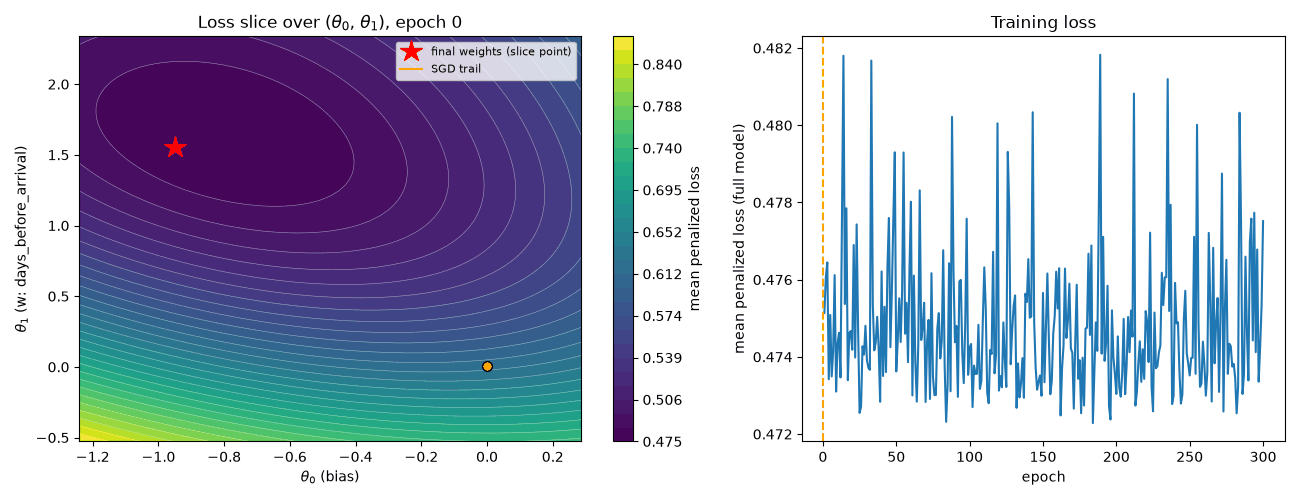

In [252]:
from IPython.display import Image, display

DBA_IDX = list(X_train_final.columns).index("days_before_arrival")

logres_anim = logres_scratch.animate_training(
    X_train_model,
    y_train_model,
    feature=DBA_IDX,
    feature_name="days_before_arrival",
)

anim_path = ROOT_DIR / "output" / "logres_contour_days_before_arrival.gif"
anim_path.parent.mkdir(exist_ok=True)
logres_anim.save(anim_path, writer="pillow", fps=20)
display(Image(filename=anim_path))

## Library

### KNN

In [253]:
knn_sklearn = KNeighborsClassifier(
    n_neighbors=3, metric="euclidean", weights="uniform"
)
knn_sklearn.fit(X_train_model, y_train_model)
knn_sklearn_val_pred = knn_sklearn.predict(X_val_model)
knn_sklearn


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### Naive Bayes


In [84]:
class SklearnMixedNB:
    def __init__(self, numeric_cols, categorical_cols, alpha=1.0, var_smoothing=1e-9, binary_cols=None):
        self.numeric_cols = numeric_cols
        self.categorical_cols = categorical_cols
        self.binary_cols = [] if binary_cols is None else list(binary_cols)
        self.alpha = alpha
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        self.classes_, counts = np.unique(y, return_counts=True)
        self.class_log_prior_ = np.log(counts / counts.sum())
        self.gaussian_models_ = {}
        for col in self.numeric_cols:
            model = GaussianNB(var_smoothing=0.0).fit(X[[col]], y)
            model.var_ += max(self.var_smoothing * X[col].to_numpy(float).var(), 1e-12)
            self.gaussian_models_[col] = model

        self.category_codes_ = {}
        self.categorical_model_ = None
        if self.categorical_cols:
            encoded = pd.DataFrame(index=X.index)
            category_counts = []
            for col in self.categorical_cols:
                codes = {value: i for i, value in enumerate(X[col].unique())}
                self.category_codes_[col] = codes
                encoded[col] = X[col].map(codes).astype(int)
                category_counts.append(len(codes) + 1)
            self.categorical_model_ = CategoricalNB(
                alpha=self.alpha, min_categories=category_counts
            ).fit(encoded, y)
        self.binary_model_ = None
        if self.binary_cols:
            if not X[self.binary_cols].isin([0, 1]).all().all():
                raise ValueError("Binary features must contain only 0 or 1.")
            self.binary_model_ = BernoulliNB(alpha=self.alpha, binarize=None).fit(
                X[self.binary_cols], y
            )
        return self

    def predict_log_proba(self, X):
        scores = np.tile(self.class_log_prior_, (len(X), 1))
        for col, model in self.gaussian_models_.items():
            scores += model.predict_log_proba(X[[col]]) - self.class_log_prior_
        if self.categorical_model_ is not None:
            encoded = pd.DataFrame(index=X.index)
            for col, codes in self.category_codes_.items():
                encoded[col] = X[col].map(codes).fillna(len(codes)).astype(int)
            scores += self.categorical_model_.predict_log_proba(encoded) - self.class_log_prior_
        if self.binary_model_ is not None:
            if not X[self.binary_cols].isin([0, 1]).all().all():
                raise ValueError("Binary features must contain only 0 or 1.")
            scores += self.binary_model_.predict_log_proba(X[self.binary_cols]) - self.class_log_prior_
        scores -= scores.max(axis=1, keepdims=True)
        return scores - np.log(np.exp(scores).sum(axis=1, keepdims=True))

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[self.predict_log_proba(X).argmax(axis=1)]

In [ ]:
nb_sklearn = SklearnMixedNB(nb_numeric_cols, nb_categorical_cols, binary_cols=nb_binary_cols)
nb_sklearn.fit(X_train_nb, y_train_nb)
nb_sklearn_val_pred = nb_sklearn.predict(X_val_nb)
nb_reference_difference = np.abs(
    nb_scratch.predict_proba(X_val_nb) - nb_sklearn.predict_proba(X_val_nb)
).max()
np.testing.assert_allclose(
    nb_scratch.predict_proba(X_val_nb), nb_sklearn.predict_proba(X_val_nb),
    rtol=1e-6, atol=1e-6,
)
np.testing.assert_array_equal(nb_val_pred, nb_sklearn_val_pred)
print("Reference: composed GaussianNB, CategoricalNB, and BernoulliNB with matched smoothing")
print("Maximum probability difference:", nb_reference_difference)
print("Prediction agreement:", np.mean(nb_val_pred == nb_sklearn_val_pred))


### SVM


In [ ]:
svm_sklearn = SVC(kernel="rbf", gamma=0.1)
svm_sklearn.fit(X_train_model, y_train_model)
svm_sklearn_val_pred = svm_sklearn.predict(X_val_model)
svm_sklearn

### Decision Tree Learning (DTL)

In [ ]:
# dtl here
# Kandidat alpha dari cost-complexity pruning path pada representasi 27 fitur yang sama
path = DecisionTreeClassifier(criterion="entropy", random_state=CFG.SEED) \
    .cost_complexity_pruning_path(X_train_encoded, y_train)
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0.5, 0.995, 25)))

# Alpha terbaik dipilih dengan 5-fold CV pada data train (sebelum oversampling)
grid = GridSearchCV(
    DecisionTreeClassifier(criterion="entropy", random_state=CFG.SEED),
    {"ccp_alpha": alphas},
    cv=StratifiedKFold(5, shuffle=True, random_state=CFG.SEED),
    scoring="accuracy", n_jobs=-1,
).fit(X_train_encoded, y_train)

best_alpha = grid.best_params_["ccp_alpha"]
print("ccp_alpha terbaik:", best_alpha)

sk_ccp = DecisionTreeClassifier(criterion="entropy", ccp_alpha=best_alpha, random_state=CFG.SEED)
sk_full = DecisionTreeClassifier(criterion="entropy", random_state=CFG.SEED)

res_sk_ccp, pred_sk, proba_sk = evaluate_tree(
    "sklearn (entropy, ccp_alpha)", sk_ccp, X_train_final, y_train_final, X_val_final, y_val, "sk")
res_sk_full, _, proba_sk_full = evaluate_tree(
    "sklearn (entropy, unpruned)", sk_full, X_train_final, y_train_final, X_val_final, y_val, "sk")
dtl_sklearn_val_pred = pred_sk

In [277]:
dtl_results = pd.DataFrame(
    [res_c45_pruned, res_c45_unpruned, res_sk_ccp, res_sk_full]
).set_index("Model")

dtl_results.style.format({
    "Train Accuracy": "{:.4f}", "Accuracy": "{:.4f}", "F1 (kelas 1)": "{:.4f}",
    "Macro-F1": "{:.4f}", "ROC-AUC": "{:.4f}", "Waktu Fit (s)": "{:.2f}",
}).highlight_max(subset=["Accuracy", "F1 (kelas 1)", "Macro-F1", "ROC-AUC"], color="#dbe8f8")

,Train Accuracy,Accuracy,F1 (kelas 1),Macro-F1,ROC-AUC,Jumlah Leaf,Kedalaman,Waktu Fit (s)
Model,,,,,,,,
"C4.5 (pruned, CF=0.25)",0.9138,0.8628,0.7874,0.8431,0.8896,795,28,15.53
C4.5 (unpruned),0.9396,0.8493,0.7705,0.8292,0.8685,1922,29,6.86
"sklearn (entropy, ccp_alpha)",0.8704,0.8566,0.7657,0.8312,0.9151,207,16,0.08
"sklearn (entropy, unpruned)",0.9998,0.8342,0.7514,0.8135,0.8163,2866,37,0.07


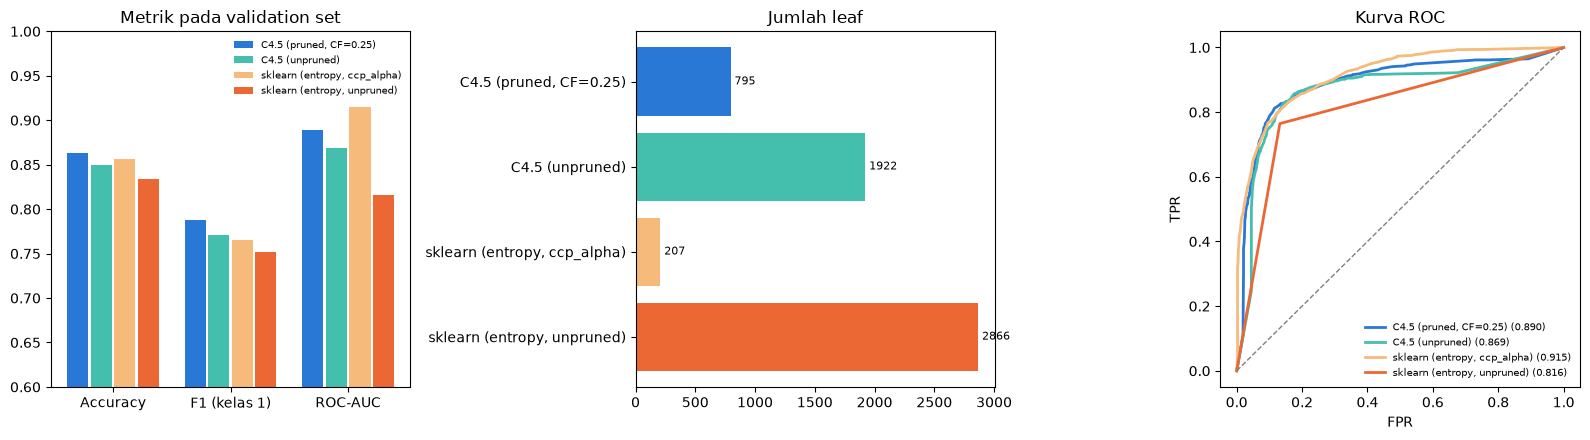

In [278]:
colors = ["#2a78d6", "#44bfad", "#f6ba7a", "#eb6834"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Accuracy, F1, ROC-AUC
metrics = ["Accuracy", "F1 (kelas 1)", "ROC-AUC"]
x = np.arange(len(metrics)); w = 0.2
for i, (name, row) in enumerate(dtl_results.iterrows()):
    axes[0].bar(x + (i - 1.5) * w, row[metrics], w - 0.02, color=colors[i], label=name)
axes[0].set_xticks(x, metrics); axes[0].set_ylim(0.6, 1.0)
axes[0].set_title("Metrik pada validation set"); axes[0].legend(fontsize=7, frameon=False)

# (b) Jumlah leaf
axes[1].barh(dtl_results.index, dtl_results["Jumlah Leaf"], color=colors)
for i, v in enumerate(dtl_results["Jumlah Leaf"]):
    axes[1].text(v, i, f" {v}", va="center", fontsize=8)
axes[1].invert_yaxis(); axes[1].set_title("Jumlah leaf")

# (c) Kurva ROC
for c, (name, p) in zip(colors, [
    ("C4.5 (pruned, CF=0.25)", proba_c45), ("C4.5 (unpruned)", proba_c45_unpruned),
    ("sklearn (entropy, ccp_alpha)", proba_sk), ("sklearn (entropy, unpruned)", proba_sk_full),
]):
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[2].plot(fpr, tpr, color=c, lw=2, label=f"{name} ({dtl_results.loc[name, 'ROC-AUC']:.3f})")
axes[2].plot([0, 1], [0, 1], "--", color="gray", lw=1)
axes[2].set_xlabel("FPR"); axes[2].set_ylabel("TPR")
axes[2].set_title("Kurva ROC"); axes[2].legend(fontsize=7, frameon=False)

plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "dtl_comparison.png", dpi=130)
plt.show()

### Logistic Regression

In [ ]:
# logres here
logres_sklearn = LogisticRegression(
    C=1.0,
    tol=1e-4,
    fit_intercept=True,
    solver="lbfgs",
    max_iter=300,
    random_state=CFG.SEED,
)
logres_sklearn.fit(X_train_model, y_train_model)
logres_sklearn_val_pred = logres_sklearn.predict(X_val_model)

## Holdout Evaluation

In [ ]:
holdout_predictions = {
    "KNN scratch": knn_val_pred,
    "Naive Bayes scratch": nb_val_pred,
    "SVM scratch": svm_val_pred,
    "DTL scratch": dtl_val_pred,
    "Logistic Regression scratch": logres_val_pred,
    "KNN sklearn": knn_sklearn_val_pred,
    "Naive Bayes sklearn": nb_sklearn_val_pred,
    "SVM sklearn": svm_sklearn_val_pred,
    "DTL sklearn": dtl_sklearn_val_pred,
    "Logistic Regression sklearn": logres_sklearn_val_pred,
}

def holdout(predictions, y_true):
    rows = {}
    for name, y_pred in predictions.items():
        rows[name] = {
            "accuracy": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
        }
    return pd.DataFrame(rows).T.sort_values(
        "f1_macro", ascending=False
    )

holdout_results = holdout(holdout_predictions, y_val_model)
holdout_results

## K-Fold Cross Validation


In [ ]:
X_train_cv_raw = X_train_raw.reset_index(drop=True).copy()
y_train_cv = y_train.reset_index(drop=True).copy()

In [ ]:
def fit_predict(model, X_fit, y_fit, X_eval):
    model.fit(X_fit, y_fit)
    return model.predict(X_eval)


def preprocess_fold(X_fit, y_fit, X_eval):
    X_fit = X_fit.copy()
    X_eval = X_eval.copy()
    y_fit = y_fit.copy()

    for data in (X_fit, X_eval):
        data.loc[data["num_adults"].eq(0), "num_adults"] = np.nan

    medians = X_fit[num_col].median()
    modes = X_fit[cat_col].mode(dropna=True).iloc[0]
    for data in (X_fit, X_eval):
        data[num_col] = data[num_col].fillna(medians)
        data[cat_col] = data[cat_col].fillna(modes)

    fold_scaler = RobustScaler()
    X_fit[num_col] = fold_scaler.fit_transform(X_fit[num_col])
    X_eval[num_col] = fold_scaler.transform(X_eval[num_col])

    fold_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    fold_encoder.fit(X_fit[cat_col])
    fold_enc_names = list(fold_encoder.get_feature_names_out(cat_col))

    fold_meal_encoder = OrdinalEncoder(
        categories=[meal_package_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )
    fold_meal_encoder.fit(X_fit[["meal_package"]])

    def encode_fold(data: pd.DataFrame) -> pd.DataFrame:
        numeric_part = data[num_col].copy()
        categorical_part = pd.DataFrame(
            fold_encoder.transform(data[cat_col]),
            columns=fold_enc_names,
            index=data.index,
        )
        categorical_part = categorical_part.drop(
            columns=[col for col in fold_enc_names if col.startswith("meal_package_")]
        )
        categorical_part["meal_package"] = fold_meal_encoder.transform(
            data[["meal_package"]]
        ).ravel()
        combined = pd.concat([numeric_part, categorical_part], axis=1)
        return combined.reindex(columns=X_train_final.columns, fill_value=0.0)

    X_fit_enc = encode_fold(X_fit)
    X_eval_enc = encode_fold(X_eval).reset_index(drop=True)

    majority_idx = y_fit[y_fit == 0].index
    minority_idx = y_fit[y_fit == 1].sample(
        n=len(majority_idx),
        replace=True,
        random_state=CFG.SEED,
    ).index
    balanced_idx = pd.Series(majority_idx.append(minority_idx)).sample(
        frac=1,
        random_state=CFG.SEED,
    ).to_numpy()

    X_fit_bal = X_fit_enc.loc[balanced_idx].reset_index(drop=True)
    y_fit_bal = y_fit.loc[balanced_idx].reset_index(drop=True)
    return X_fit_bal, y_fit_bal, X_eval_enc


def build_cv_folds(X, y, n_splits=5):
    folds = StratifiedKFold(
        n_splits=n_splits, shuffle=True, random_state=CFG.SEED
    )
    cv_folds = []
    for fit_index, eval_index in folds.split(X, y):
        X_fit_bal, y_fit_bal, X_eval_enc = preprocess_fold(
            X.iloc[fit_index], y.iloc[fit_index], X.iloc[eval_index]
        )
        y_eval = y.iloc[eval_index].reset_index(drop=True)
        cv_folds.append((X_fit_bal, y_fit_bal, X_eval_enc, y_eval))
    return cv_folds


def kfold_scores(model_factory, cv_folds):
    scores = []
    for X_fit, y_fit, X_eval, y_eval in cv_folds:
        model = model_factory()
        y_pred = fit_predict(model, X_fit, y_fit, X_eval)
        scores.append(
            f1_score(y_eval, y_pred, average="macro", zero_division=0)
        )
    return np.asarray(scores)


def kfold(model_factories, cv_folds):
    rows = {}
    for name, model_factory in model_factories.items():
        scores = kfold_scores(model_factory, cv_folds)
        rows[name] = {"kfold_mean": scores.mean(), "kfold_std": scores.std()}
    return pd.DataFrame(rows).T

In [ ]:
cv_folds = build_cv_folds(X_train_cv_raw, y_train_cv, n_splits=5)

kfold_factories = {
    "KNN scratch": lambda: KNN(k=3),
    "Naive Bayes scratch": lambda: NaiveBayes(
        numeric_cols=nb_numeric_cols,
        categorical_cols=nb_categorical_cols,
        binary_cols=nb_binary_cols,
    ),
    "SVM scratch": lambda: svm(kernel="rbf", gamma=0.1),
    "DTL scratch": lambda: DecisionTreeC45(prune=True, confidence_factor=0.25),
    "Logistic Regression scratch": lambda: LogRes(
        learn_rate=0.01,
        iterations=300,
        penalty="l2",
        C=1.0,
        tolerance=1e-4,
        fit_intercept=True,
        shuffle=True,
        verbose=False,
        random_seed=CFG.SEED,
    ),
    "KNN sklearn": lambda: KNeighborsClassifier(
        n_neighbors=3, metric="euclidean", weights="uniform"
    ),
    "Naive Bayes sklearn": lambda: SklearnMixedNB(nb_numeric_cols, nb_categorical_cols, binary_cols=nb_binary_cols),
    "SVM sklearn": lambda: SVC(kernel="rbf", gamma=0.1),
    "DTL sklearn": lambda: DecisionTreeClassifier(
        criterion="entropy", ccp_alpha=best_alpha, random_state=CFG.SEED
    ),
    "Logistic Regression sklearn": lambda: LogisticRegression(
        C=1.0,
        tol=1e-4,
        fit_intercept=True,
        solver="lbfgs",
        max_iter=300,
        random_state=CFG.SEED,
    ),
}

kfold_results = kfold(kfold_factories, cv_folds)
kfold_results

## Compare


In [ ]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values(
        "kfold_mean", ascending=False
    )

comparison_results = compare(holdout_results, kfold_results)
comparison_results


---

# Saving and Loading Models <a name="9"></a>

---

In [ ]:
import pickle

model_files = [
    ("nb_scratch", "X_val_nb", "NaiveBayes.pkl"),
    ("svm_scratch", "X_val_model", "SVM.pkl"),
    ("dtl_pruned", "X_val_final", "DTL_pruned.pkl"),
    ("logres_scratch", "X_val_model", "LogRes.pkl"),
]

loaded_models = {}
save_load_results = []
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, input_name, filename in model_files:
    if name not in globals():
        print(f"Skipped {name}: model is not available; run its training cell first.")
        continue
    model = globals()[name]
    X_check = globals()[input_name]
    original_predictions = model.predict(X_check)
    model_path = CFG.OUTPUT_DIR / filename
    with open(model_path, "wb") as file:
        pickle.dump(model, file)
    with open(model_path, "rb") as file:
        loaded_model = pickle.load(file)
    np.testing.assert_array_equal(original_predictions, loaded_model.predict(X_check))
    if hasattr(model, "predict_proba"):
        np.testing.assert_allclose(
            model.predict_proba(X_check), loaded_model.predict_proba(X_check),
            rtol=0, atol=0,
        )
    loaded_models[name] = loaded_model
    save_load_results.append({"model": name, "file": filename, "verified": True})

nb_loaded = loaded_models.get("nb_scratch")
pd.DataFrame(save_load_results)


---

# Kaggle Submission <a name="10"></a>

---

In [265]:
def submit(model, X_train, y_train, X_val, y_val, X_test):
    X = pd.concat([X_train, X_val])
    y = pd.concat([y_train, y_val])

    predictions = fit_predict(model, X, y, X_test)

    result = pd.DataFrame({
        ID_COL: test_ids.to_numpy(),
        TARGET_COL: predictions,
    })

    path = ROOT_DIR / "submission.csv"
    result.to_csv(path, index=False)
    print(f"{len(result)} rows written to {path}")

    return result.head()

In [267]:
submit(
    model=DecisionTreeC45(prune=True, confidence_factor=0.67),
    X_train=X_train_imputed,
    y_train=y_train,
    X_val=X_val_imputed,
    y_val=y_val,
    X_test=X_test_imputed,
)

6844 rows written to /Users/dzaki/Edukasi/Kuliah/Semester_5/AI/IF3170_G05_Aksin-ya/submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Error analysis inspects the wrong predictions on the validation split. The models are not refitted; every function reads the predictions from Holdout Evaluation.

## Confusion Matrix

Confusion matrices and per-class precision, recall, and F1-score of every model.

In [ ]:
def confusion(predictions, y_true, per_row=5):
    n_cols = min(per_row, len(predictions))
    n_rows = -(-len(predictions) // n_cols)
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 3.6 * n_rows), squeeze=False
    )
    for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, ax=ax, colorbar=False)
        ax.set_title(name)
    for ax in axes.flat[len(predictions):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()

confusion(holdout_predictions, y_val_model)

In [ ]:
def report(predictions, y_true):
    tables = {}
    for name, y_pred in predictions.items():
        tables[name] = pd.DataFrame(
            classification_report(y_true, y_pred, output_dict=True, zero_division=0)
        ).T
    return pd.concat(tables)

report_results = report(holdout_predictions, y_val_model)
report_results

## Misclassified Patterns

In [ ]:
def misclassified(y_pred, y_true):
    y_pred = pd.Series(np.asarray(y_pred), index=y_true.index)
    wrong = y_pred[y_pred != y_true]
    return train_df.loc[wrong.index].assign(predicted=wrong)

misclassified(holdout_predictions[holdout_results.index[0]], y_val)